In [1]:
!pip install -q timm safetensors torch torchvision numpy requests matplotlib scipy tqdm psutil


# One-Round FedAvg Global-Update Inversion

The previous notebook considered the strongest server-side observation: a single user's local update. In this notebook, we move one step closer to a standard federated learning round.

Multiple clients now train locally from the same global model. The server aggregates their updates with **FedAvg** and then attempts reconstruction from the **aggregated global-model update**.

The server is not reconstructing private data from a standalone trained model. It knows the global model before the round, $\theta_t$, and the model after aggregation, $\theta_{t+1}$.

The question is whether information about the participating clients can still be recovered after their updates have been mixed by aggregation.

We continue to use the lightweight **MobileNetV4 Conv Small 0.5** checkpoint produced in the centralized fine-tuning stage. The backbone remains frozen and clients update only the classifier head. This keeps the experiment computationally small and makes the source of information leakage easier to inspect.


## Experimental design

We simulate one communication round with $m \in \{1,2,5,10\}$ participating clients.

Each client holds between 4 and 8 private QuickDraw images. Classes are unique inside one client, although the same class may occur in different clients. Each selected client performs exactly **one local SGD step** on the classifier head.

The server then computes standard sample-weighted FedAvg. Under the controlled assumptions used in this notebook, one local step, a shared learning rate, mean-reduction loss, and a frozen backbone, each client update is

$$
\Delta_k = -\eta g_k.
$$

Therefore,

$$
-\frac{\Delta_{\mathrm{global}}}{\eta}
=
\sum_{k=1}^{m}\frac{n_k}{N}g_k.
$$

This is exactly the gradient of the pooled virtual batch formed by all samples from the participating clients. The server never needs to observe the individual $\Delta_k$ values to construct this aggregate target.

This equivalence is specific to the experimental setup. With multiple local steps, local optimizer state, heterogeneous learning rates, or backbone updates, the relationship between a model delta and a single pooled gradient is no longer exact.


## What the attacker tries to recover

The aggregate contains images from several clients, so the attack is more difficult than the single-client case.

The attack proceeds in two stages:

1. **Recover aggregate label counts.** The same class may appear at several clients, so the target is a count vector over the 10 global classes, not only a set of labels. Recovery uses class-gradient prototypes computed from separate public QuickDraw samples.
2. **Reconstruct images.** One 28x28 canvas is optimized for each recovered label occurrence. The optimization matches the aggregate classifier-head gradient while using mild QuickDraw image priors.

The public samples used by the attacker come from a different index range than the simulated private samples. They provide class-level prior information, not access to a victim's image.

Ground-truth private images and labels are used only after the attack for simulation evaluation.


## Imports and runtime configuration


In [2]:
import os
import json
import copy
import random
import urllib.request
import threading
import time

import psutil
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment, minimize

import timm
import timm.data as timm_data
from safetensors.torch import load_file as load_safetensors
from safetensors.torch import save_file as save_safetensors



SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"Using device: {DEVICE}")

# Stage 1 artifacts expected from the centralized fine-tuning notebook.
STAGE1_OUTPUT_DIR = Path("./outputs")
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./outputs_attack2_multi_user_v2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# FedAvg sweep. m=1 is intentionally included: it is the Attack 1 limit case.
M_VALUES = [1, 2, 5, 10]
MAX_CLIENTS = max(M_VALUES)

# Each client holds a random number of images/classes in [4, 8]. Classes are unique inside a
# client. Across clients, classes may repeat, so the aggregate target contains label counts.
MIN_IMAGES_PER_CLIENT = 4
MAX_IMAGES_PER_CLIENT = 8

# Two global classes are never assigned to any user. This makes the multi-user setting more
# interpretable: the attacker should ideally assign zero count to these out-of-range classes.
# The default attack does NOT assume this exclusion list is known; it searches over all 10
# classes. Set ATTACKER_KNOWS_EXCLUDED_CLASSES=True only for an oracle/ablation run.
EXCLUDED_CLASS_NAMES = ["tshirt", "donut"]
ATTACKER_KNOWS_EXCLUDED_CLASSES = False

# Local training: exactly one head-only SGD step. This makes the aggregate FedAvg delta exactly
# recoverable as a pooled gradient via g = -Δ / lr.
LOCAL_STEPS = 1
LOCAL_LR = 1e-2

# Private data selection. "hard" samples give stronger gradients and more visible leakage;
# they are selected by scoring random candidates under the starting global model and taking
# the highest-loss example for the intended class.
USER_SAMPLE_MODE = "hard"  # "hard" or "random"
PRIVATE_INDEX_MIN = 20000
HARD_SAMPLE_CANDIDATES_PER_CLASS = 128

# Public samples used by the attacker. These are deliberately drawn from a different index
# range than private samples. They are not the users' data; they are used only as class priors.
PUBLIC_INDEX_MAX = 20000
PUBLIC_GRAD_REF_PER_CLASS = 96
PUBLIC_PRIOR_LOGIT_EPS = 0.02
PUBLIC_PRIOR_NOISE = 0.20

# Label-count recovery. We solve a small continuous constrained least-squares problem over
# class counts and then round to integer counts. The objective compares the aggregate gradient
# to a non-negative combination of public per-class gradient prototypes.
COUNT_RECOVERY_BIAS_WEIGHT = 10.0
COUNT_TOP_CLASSES_TO_PRINT = 10

# Pixel reconstruction schedules. Multi-user inversion can be expensive because the number of
# candidate canvases grows with the total sample count N. The defaults below are chosen for a
# live-demo runtime. Increase the number of steps/restarts for cleaner figures.
PIXEL_ATTACK_STEPS_BY_M = {
    1: 2500,
    2: 2000,
    5: 1500,
    10: 1000,
}
PIXEL_ATTACK_RESTARTS_BY_M = {
    1: 5,
    2: 3,
    5: 2,
    10: 1,
}
PIXEL_ATTACK_LR = 0.01
PIXEL_GRAD_CLIP_NORM = 1.0
TRACK_BEST_PIXEL_STEP = True

# Optional oracle diagnostic. This uses the true aggregate label counts, so it is not an
# attacker capability; it is only a debugging/evaluation check. Keeping it to m=1 by default
# confirms that the multi-user code reduces to the Attack 1 setting when the labels/counts are
# known exactly, without doubling the full m-sweep runtime.
RUN_ORACLE_COUNT_PIXEL_DIAGNOSTIC = True
ORACLE_COUNT_PIXEL_DIAGNOSTIC_M_VALUES = [1]

# Direct 28x28 image-prior weights. The reconstruction objective is gradient matching plus
# mild QuickDraw priors: smoothness, sparse black background, and near-binary pixels.
GRAD_B_WEIGHT = 10.0
TV_WEIGHT = 0.01
SPARSITY_WEIGHT = 0.001
BINARY_WEIGHT = 0.001

# Plotting: for large m, plotting every sample becomes unreadable. We still compute metrics on
# all samples, but figures show a compact subset.
MAX_PLOT_PAIRS_PER_M = 12


Using device: cuda


## Utility functions

The helper functions cover QuickDraw loading, image preprocessing, feature extraction, analytic classifier-head gradients, JSON serialization, and scoped resource measurement.

For each aggregate attack experiment we report wall-clock runtime, peak process RAM, and CUDA peak allocated/reserved VRAM when a CUDA device is available. Process RAM is sampled during the experiment at 50 ms intervals.


In [3]:
def download_quickdraw_dataset(root: Path, file_names: List[str]) -> None:
    """Download selected QuickDraw `.npy` files if they are not already present."""
    root.mkdir(parents=True, exist_ok=True)
    base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

    print("Downloading QuickDraw dataset files used by the Stage 1 label space...")
    for file_name in tqdm(file_names):
        fpath = root / f"{file_name}.npy"
        if fpath.exists():
            continue

        url_file_name = file_name.replace("_", "%20").replace("-", "%2D")
        url = f"{base_url}{url_file_name}.npy"
        try:
            urllib.request.urlretrieve(url, fpath)
        except Exception as e:
            raise RuntimeError(f"Failed to download class file '{file_name}' from {url}: {e}")
    print("Download complete.")


def preprocess_images(raw_imgs: List[np.ndarray], transform) -> torch.Tensor:
    """Convert raw 28x28 QuickDraw uint8 images to normalized model tensors."""
    tensors = []
    for img in raw_imgs:
        img_rgb = np.stack([img, img, img], axis=-1)
        pil_img = Image.fromarray(img_rgb)
        tensors.append(transform(pil_img))
    return torch.stack(tensors)


def embedding_of(model: nn.Module, images_3ch: torch.Tensor) -> torch.Tensor:
    """Return pooled backbone embeddings for normalized model inputs.

    This function must remain differentiable when used by the pixel inversion attack. Call it
    inside ``with torch.no_grad():`` only in evaluation/precomputation code. Do not decorate
    the function itself with ``@torch.no_grad()``, otherwise the image optimizer receives no
    gradient from the gradient-matching objective and collapses to black images.
    """
    feats = model.forward_features(images_3ch)
    pooled = model.forward_head(feats, pre_logits=True)
    return pooled


@torch.no_grad()
def evaluate_head_on_batch(
    embeddings: torch.Tensor,
    labels: torch.Tensor,
    W: torch.Tensor,
    b: torch.Tensor,
) -> Tuple[float, float, List[int]]:
    """Evaluate the classifier head on a batch of already-computed embeddings."""
    logits = embeddings @ W.t() + b
    loss = F.cross_entropy(logits, labels).item()
    preds = logits.argmax(dim=1)
    acc = 100.0 * (preds == labels).float().mean().item()
    return loss, acc, preds.detach().cpu().tolist()


def analytic_head_gradient(
    embeddings: torch.Tensor,
    labels: torch.Tensor,
    W: torch.Tensor,
    b: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Compute the exact mean-reduction cross-entropy gradient for a linear head.

    This avoids repeatedly calling `torch.autograd.grad` inside the attack loop. For logits
    z_i = W h_i + b and cross-entropy with mean reduction:

        grad_b = mean_i(p_i - onehot(y_i))
        grad_W = grad_b_per_sample^T @ h

    The returned tensors remain differentiable with respect to `embeddings`, which is needed
    during pixel optimization.
    """
    logits = embeddings @ W.t() + b
    probs = F.softmax(logits, dim=1)
    onehot = F.one_hot(labels, num_classes=W.shape[0]).to(dtype=embeddings.dtype)
    diff = (probs - onehot) / labels.numel()
    grad_b = diff.sum(dim=0)
    grad_W = diff.t() @ embeddings
    return grad_W, grad_b


def compute_mse(a: np.ndarray, b: np.ndarray) -> float:
    """MSE on uint8-like arrays in [0, 255]."""
    return float(np.mean((a.astype(np.float32) - b.astype(np.float32)) ** 2))


def compute_psnr(mse: float, max_val: float = 255.0) -> float:
    """Peak signal-to-noise ratio from MSE."""
    if mse == 0:
        return float("inf")
    return float(20 * np.log10(max_val) - 10 * np.log10(mse))


def compute_simple_ssim(a: np.ndarray, b: np.ndarray) -> float:
    """Simple global SSIM approximation used consistently across the tutorial notebooks."""
    a = a.astype(np.float64)
    b = b.astype(np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mu_a, mu_b = a.mean(), b.mean()
    var_a, var_b = a.var(), b.var()
    cov_ab = ((a - mu_a) * (b - mu_b)).mean()
    return float(((2 * mu_a * mu_b + c1) * (2 * cov_ab + c2)) / ((mu_a ** 2 + mu_b ** 2 + c1) * (var_a + var_b + c2)))


def summarize_metric_lists(mses: List[float], psnrs: List[float], ssims: List[float]) -> Dict[str, float]:
    """Return mean metrics, handling empty lists safely."""
    if len(mses) == 0:
        return {"mse": float("nan"), "psnr_db": float("nan"), "ssim": float("nan")}
    return {
        "mse": float(np.mean(mses)),
        "psnr_db": float(np.mean(psnrs)),
        "ssim": float(np.mean(ssims)),
    }


def raw_to_logit_canvas(raw_img: np.ndarray, eps: float = PUBLIC_PRIOR_LOGIT_EPS) -> torch.Tensor:
    """Convert a public 28x28 uint8 prior image to an unconstrained logit canvas."""
    arr = torch.tensor(raw_img.astype(np.float32) / 255.0)
    arr = arr.clamp(eps, 1.0 - eps)
    logit = torch.log(arr / (1.0 - arr))
    return logit.view(1, 28, 28)


def save_json(path: Path, payload: Dict) -> None:
    """Save JSON with float-safe conversion."""
    def convert(x):
        if isinstance(x, np.ndarray):
            return x.tolist()
        if isinstance(x, (np.float32, np.float64)):
            return float(x)
        if isinstance(x, (np.int32, np.int64)):
            return int(x)
        if isinstance(x, dict):
            return {k: convert(v) for k, v in x.items()}
        if isinstance(x, list):
            return [convert(v) for v in x]
        return x

    with open(path, "w") as f:
        json.dump(convert(payload), f, indent=2)

def start_resource_monitor(device: torch.device, sample_interval_s: float = 0.05) -> Dict:
    """Start scoped wall-time, process-RAM, and CUDA-VRAM monitoring."""
    process = psutil.Process(os.getpid())
    baseline_rss = process.memory_info().rss
    rss_samples = [baseline_rss]
    stop_event = threading.Event()

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)
        baseline_cuda_allocated = torch.cuda.memory_allocated(device)
        baseline_cuda_reserved = torch.cuda.memory_reserved(device)
    else:
        baseline_cuda_allocated = None
        baseline_cuda_reserved = None

    def sample_ram():
        while not stop_event.is_set():
            rss_samples.append(process.memory_info().rss)
            stop_event.wait(sample_interval_s)

    thread = threading.Thread(target=sample_ram, daemon=True)
    thread.start()

    return {
        "process": process,
        "baseline_rss": baseline_rss,
        "rss_samples": rss_samples,
        "stop_event": stop_event,
        "thread": thread,
        "start_time": time.perf_counter(),
        "baseline_cuda_allocated": baseline_cuda_allocated,
        "baseline_cuda_reserved": baseline_cuda_reserved,
    }


def stop_resource_monitor(monitor: Dict, device: torch.device) -> Dict:
    """Stop monitoring and return JSON-serializable runtime and memory statistics."""
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    elapsed_s = time.perf_counter() - monitor["start_time"]
    monitor["stop_event"].set()
    monitor["thread"].join(timeout=1.0)
    monitor["rss_samples"].append(monitor["process"].memory_info().rss)

    peak_rss = max(monitor["rss_samples"])
    baseline_rss = monitor["baseline_rss"]

    stats = {
        "elapsed_s": float(elapsed_s),
        "baseline_process_ram_mib": float(baseline_rss / (1024 ** 2)),
        "peak_process_ram_mib": float(peak_rss / (1024 ** 2)),
        "peak_process_ram_increase_mib": float((peak_rss - baseline_rss) / (1024 ** 2)),
        "ram_sampling_interval_s": 0.05,
        "peak_cuda_vram_allocated_mib": None,
        "peak_cuda_vram_reserved_mib": None,
        "peak_cuda_vram_allocated_increase_mib": None,
        "peak_cuda_vram_reserved_increase_mib": None,
    }

    if device.type == "cuda":
        peak_allocated = torch.cuda.max_memory_allocated(device)
        peak_reserved = torch.cuda.max_memory_reserved(device)
        stats.update({
            "peak_cuda_vram_allocated_mib": float(peak_allocated / (1024 ** 2)),
            "peak_cuda_vram_reserved_mib": float(peak_reserved / (1024 ** 2)),
            "peak_cuda_vram_allocated_increase_mib": float(
                (peak_allocated - monitor["baseline_cuda_allocated"]) / (1024 ** 2)
            ),
            "peak_cuda_vram_reserved_increase_mib": float(
                (peak_reserved - monitor["baseline_cuda_reserved"]) / (1024 ** 2)
            ),
        })

    return stats


def print_resource_stats(stats: Dict, prefix: str = "") -> None:
    print(f"{prefix}Runtime: {stats['elapsed_s']:.2f} s")
    print(f"{prefix}Peak process RAM (RSS): {stats['peak_process_ram_mib']:.1f} MiB "
          f"(+{stats['peak_process_ram_increase_mib']:.1f} MiB over start)")
    if stats["peak_cuda_vram_allocated_mib"] is not None:
        print(f"{prefix}Peak CUDA VRAM allocated: {stats['peak_cuda_vram_allocated_mib']:.1f} MiB "
              f"(+{stats['peak_cuda_vram_allocated_increase_mib']:.1f} MiB)")
        print(f"{prefix}Peak CUDA VRAM reserved: {stats['peak_cuda_vram_reserved_mib']:.1f} MiB "
              f"(+{stats['peak_cuda_vram_reserved_increase_mib']:.1f} MiB)")
    else:
        print(f"{prefix}CUDA VRAM: not applicable on device={DEVICE}")


## Load the common global initialization

All clients start from the same checkpoint produced by the centralized fine-tuning notebook.

The notebook explicitly checks that the checkpoint configuration uses:

`mobilenetv4_conv_small_050.e3000_r224_in1k`

Only the classifier head participates in the simulated FL update. The MobileNetV4 backbone is frozen.


In [4]:
config_path = STAGE1_OUTPUT_DIR / "config.json"
with open(config_path, "r") as f:
    stage1_config = json.load(f)

MODEL_NAME = stage1_config["model_name"]
EXPECTED_MODEL_NAME = "mobilenetv4_conv_small_050.e3000_r224_in1k"
assert MODEL_NAME == EXPECTED_MODEL_NAME, (
    f"This notebook expects the FLTA Small MobileNetV4 checkpoint ({EXPECTED_MODEL_NAME}), "
    f"but config.json specifies {MODEL_NAME}."
)
ALL_CLASS_NAMES = stage1_config["class_names"]
QUICKDRAW_FILE_NAMES = stage1_config["quickdraw_file_names"]
IMG_SIZE = stage1_config["input_size"][-1]
MEAN = stage1_config["mean"]
STD = stage1_config["std"]
NUM_CLASSES = stage1_config["num_classes"]

print(f"Stage 1 model: {MODEL_NAME}")
print(f"Stage 1 classes ({NUM_CLASSES}): {ALL_CLASS_NAMES}")
print(f"Excluded/out-of-range classes: {EXCLUDED_CLASS_NAMES}")

candidate_ckpts = list(STAGE1_OUTPUT_DIR.glob("*.safetensors"))
assert len(candidate_ckpts) >= 1, f"No .safetensors checkpoint found in {STAGE1_OUTPUT_DIR}"
STAGE1_CKPT_PATH = candidate_ckpts[0]
print(f"Stage 1 checkpoint: {STAGE1_CKPT_PATH}")

# Load global model θ_t.
global_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES)
num_model_params = sum(p.numel() for p in global_model.parameters())
print(f"Model parameters: {num_model_params:,}")
stage1_state_dict = load_safetensors(str(STAGE1_CKPT_PATH))
missing, unexpected = global_model.load_state_dict(stage1_state_dict, strict=True)
print(f"Loaded Stage 1 weights. Missing: {missing} | Unexpected: {unexpected}")

global_model.to(DEVICE)
global_model.eval()
for p in global_model.parameters():
    p.requires_grad = False

classifier_module = global_model.get_classifier()
W_global = classifier_module.weight.detach().clone().to(DEVICE)
b_global = classifier_module.bias.detach().clone().to(DEVICE)
embed_dim = W_global.shape[1]
print(f"Frozen global head: W shape {tuple(W_global.shape)}, b shape {tuple(b_global.shape)}")

# Download/load QuickDraw class files.
download_quickdraw_dataset(DATA_DIR, QUICKDRAW_FILE_NAMES)
print("Available data files:", sorted(os.listdir(DATA_DIR)))

file_names_lookup = dict(zip(ALL_CLASS_NAMES, QUICKDRAW_FILE_NAMES))
class_to_idx = {c: i for i, c in enumerate(ALL_CLASS_NAMES)}
excluded_indices = [class_to_idx[c] for c in EXCLUDED_CLASS_NAMES]
allowed_class_names = [c for c in ALL_CLASS_NAMES if c not in EXCLUDED_CLASS_NAMES]
allowed_class_indices = [class_to_idx[c] for c in allowed_class_names]
print(f"Allowed user classes ({len(allowed_class_names)}): {allowed_class_names}")

# Transform matching the Stage 1 MobileNet preprocessing.
data_config = {
    "input_size": (3, IMG_SIZE, IMG_SIZE),
    "mean": MEAN,
    "std": STD,
}
eval_transform = timm_data.create_transform(**data_config, is_training=False)
print(eval_transform)

mean_t = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=DEVICE).view(1, 3, 1, 1)


Stage 1 model: mobilenetv4_conv_small_050.e3000_r224_in1k
Stage 1 classes (10): ['line', 'circle', 'square', 'triangle', 'star', 'tshirt', 'smiley_face', 'sun', 'cloud', 'donut']
Excluded/out-of-range classes: ['tshirt', 'donut']
Stage 1 checkpoint: outputs/mobilenetv4_small_quickdraw10.safetensors
Model parameters: 970,762
Loaded Stage 1 weights. Missing: [] | Unexpected: []
Frozen global head: W shape (10, 1280), b shape (10,)


  0%|          | 0/10 [00:00<?, ?it/s]

Download complete.
Available data files: ['circle.npy', 'cloud.npy', 'donut.npy', 'line.npy', 'smiley_face.npy', 'square.npy', 'star.npy', 'sun.npy', 't-shirt.npy', 'triangle.npy']
Allowed user classes (8): ['line', 'circle', 'square', 'triangle', 'star', 'smiley_face', 'sun', 'cloud']
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)


## Build the simulated client pool

A reusable pool of clients is generated once so that the experiments with 1, 2, 5, and 10 clients are nested and comparable.

Each client receives between 4 and 8 images from distinct classes. Two classes are intentionally not assigned to clients. The attacker is not told this exclusion by default.

The default `"hard"` sampling mode selects higher-loss examples from a private candidate range. This is an experimental stress setting designed to create stronger local gradients and visible leakage.

For every client, the notebook computes one head-only SGD update from the common starting global model.


In [5]:
def choose_private_index(
    data: np.ndarray,
    rng: np.random.Generator,
    used: set,
    index_min: int = PRIVATE_INDEX_MIN,
) -> int:
    """Choose a private data index, avoiding previously used indices for that class."""
    for _ in range(1000):
        idx = int(rng.integers(index_min, data.shape[0]))
        if idx not in used:
            used.add(idx)
            return idx
    raise RuntimeError("Could not sample a unique private index after many attempts.")


def sample_hard_private_image(
    cls_name: str,
    cls_idx: int,
    rng: np.random.Generator,
    used_indices_for_class: set,
) -> Tuple[np.ndarray, int, float]:
    """Sample a high-loss private image for one class under the current global model."""
    fname = file_names_lookup[cls_name]
    fpath = DATA_DIR / f"{fname}.npy"
    data = np.load(fpath, mmap_mode="r")

    if USER_SAMPLE_MODE == "random":
        idx = choose_private_index(data, rng, used_indices_for_class)
        raw = np.array(data[idx]).reshape(28, 28).astype(np.uint8)
        X = preprocess_images([raw], eval_transform).to(DEVICE)
        with torch.no_grad():
            emb = embedding_of(global_model, X)
            y = torch.tensor([cls_idx], dtype=torch.long, device=DEVICE)
            loss, _, _ = evaluate_head_on_batch(emb, y, W_global, b_global)
        return raw, idx, loss

    # Hard mode: score several random candidates and keep the one with the highest CE loss.
    candidate_indices = []
    candidate_raw = []
    for _ in range(HARD_SAMPLE_CANDIDATES_PER_CLASS):
        idx = choose_private_index(data, rng, used_indices_for_class)
        candidate_indices.append(idx)
        candidate_raw.append(np.array(data[idx]).reshape(28, 28).astype(np.uint8))

    X = preprocess_images(candidate_raw, eval_transform).to(DEVICE)
    y = torch.full((len(candidate_raw),), cls_idx, dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        emb = embedding_of(global_model, X)
        logits = emb @ W_global.t() + b_global
        losses = F.cross_entropy(logits, y, reduction="none")

    best_pos = int(torch.argmax(losses).item())
    return candidate_raw[best_pos], candidate_indices[best_pos], float(losses[best_pos].item())


def build_client_pool(max_clients: int) -> List[Dict]:
    """Create a deterministic pool of clients; m uses the first m clients from this pool."""
    rng = np.random.default_rng(SEED + 200)
    used_by_class = {c: set() for c in ALL_CLASS_NAMES}
    clients = []

    print(f"\nBuilding a pool of {max_clients} clients...")
    for client_id in range(max_clients):
        n_local = int(rng.integers(MIN_IMAGES_PER_CLIENT, MAX_IMAGES_PER_CLIENT + 1))
        client_classes = rng.choice(allowed_class_names, size=n_local, replace=False).tolist()

        raw_images, labels, selected_indices, losses = [], [], [], []
        print(f"\nClient {client_id:02d}: n={n_local}, classes={client_classes}")
        for cls_name in client_classes:
            cls_idx = class_to_idx[cls_name]
            raw, idx, loss = sample_hard_private_image(
                cls_name=cls_name,
                cls_idx=cls_idx,
                rng=rng,
                used_indices_for_class=used_by_class[cls_name],
            )
            raw_images.append(raw)
            labels.append(cls_idx)
            selected_indices.append(idx)
            losses.append(loss)
            print(f"  selected idx={idx:6d} for class {cls_name:<12s} (loss={loss:.4f})")

        X = preprocess_images(raw_images, eval_transform).to(DEVICE)
        y = torch.tensor(labels, dtype=torch.long, device=DEVICE)
        with torch.no_grad():
            emb = embedding_of(global_model, X)
            before_loss, before_acc, before_preds = evaluate_head_on_batch(emb, y, W_global, b_global)
            gW, gb = analytic_head_gradient(emb, y, W_global, b_global)

            # One-step local SGD on the head only.
            W_local = W_global - LOCAL_LR * gW
            b_local = b_global - LOCAL_LR * gb
            after_loss, after_acc, after_preds = evaluate_head_on_batch(emb, y, W_local, b_local)

        clients.append({
            "client_id": client_id,
            "n": n_local,
            "class_names": client_classes,
            "labels": labels,
            "raw_images": raw_images,
            "selected_indices": selected_indices,
            "selection_losses": losses,
            "embeddings": emb.detach(),
            "grad_W": gW.detach(),
            "grad_b": gb.detach(),
            "delta_W": (-LOCAL_LR * gW).detach(),
            "delta_b": (-LOCAL_LR * gb).detach(),
            "before_loss": before_loss,
            "before_acc": before_acc,
            "before_preds": before_preds,
            "after_loss": after_loss,
            "after_acc": after_acc,
            "after_preds": after_preds,
        })
        print(f"  before local step: loss={before_loss:.4f}, acc={before_acc:.1f}%")
        print(f"  after  local step: loss={after_loss:.4f}, acc={after_acc:.1f}%")

    return clients


clients_pool = build_client_pool(MAX_CLIENTS)



Building a pool of 10 clients...

Client 00: n=8, classes=['smiley_face', 'square', 'circle', 'sun', 'cloud', 'star', 'line', 'triangle']
  selected idx=102009 for class smiley_face  (loss=2.0004)
  selected idx= 46582 for class square       (loss=5.3660)
  selected idx= 33505 for class circle       (loss=8.8162)
  selected idx=103369 for class sun          (loss=0.1829)
  selected idx= 87446 for class cloud        (loss=1.3321)
  selected idx= 60732 for class star         (loss=8.8188)
  selected idx= 99344 for class line         (loss=8.6976)
  selected idx= 60977 for class triangle     (loss=7.3649)
  before local step: loss=5.3224, acc=12.5%
  after  local step: loss=5.0520, acc=12.5%

Client 01: n=4, classes=['circle', 'square', 'star', 'cloud']
  selected idx= 32608 for class circle       (loss=11.7640)
  selected idx= 88679 for class square       (loss=5.9689)
  selected idx= 90505 for class star         (loss=2.4768)
  selected idx=102794 for class cloud        (loss=0.5387)
 

## Build public class-gradient prototypes

The server-side attacker knows the global label space and has access to unrelated public QuickDraw samples.

For each class, public examples are passed through the same frozen feature extractor and used to estimate a representative classifier-head gradient. These prototypes are later used to infer how many examples of each class are consistent with the observed aggregate gradient.

This is an explicit attacker prior. The attacker does not use any of the simulated private images to build these prototypes.


In [6]:
def sample_public_images_for_class(
    cls_name: str,
    count: int,
    rng: np.random.Generator,
    index_max: int = PUBLIC_INDEX_MAX,
) -> List[np.ndarray]:
    """Sample unrelated public QuickDraw images for one class."""
    fname = file_names_lookup[cls_name]
    fpath = DATA_DIR / f"{fname}.npy"
    data = np.load(fpath, mmap_mode="r")
    max_index = min(index_max, data.shape[0])
    indices = rng.choice(max_index, size=count, replace=False)
    return [np.array(data[int(idx)]).reshape(28, 28).astype(np.uint8) for idx in indices]


def compute_public_gradient_prototypes() -> Tuple[np.ndarray, np.ndarray]:
    """Estimate average per-class head-gradient prototypes from public images.

    For each candidate true class c, the prototype is the average single-sample gradient that
    an unrelated public image of class c would induce on the frozen classifier head.
    """
    rng = np.random.default_rng(SEED + 300)
    proto_W = []
    proto_b = []

    print("\nComputing public per-class gradient prototypes for label-count recovery...")
    for cls_idx, cls_name in enumerate(tqdm(ALL_CLASS_NAMES)):
        raw_list = sample_public_images_for_class(cls_name, PUBLIC_GRAD_REF_PER_CLASS, rng)
        X = preprocess_images(raw_list, eval_transform).to(DEVICE)
        y = torch.full((len(raw_list),), cls_idx, dtype=torch.long, device=DEVICE)

        with torch.no_grad():
            emb = embedding_of(global_model, X)
            logits = emb @ W_global.t() + b_global
            probs = F.softmax(logits, dim=1)
            onehot = F.one_hot(y, num_classes=NUM_CLASSES).float()
            diff = probs - onehot

            # Average single-sample gradients for samples whose true label is cls_idx.
            avg_b = diff.mean(dim=0)
            avg_W = diff.t() @ emb / len(raw_list)

        proto_W.append(avg_W.cpu().numpy())
        proto_b.append(avg_b.cpu().numpy())

    proto_W_np = np.stack(proto_W, axis=0)  # (C, C, D)
    proto_b_np = np.stack(proto_b, axis=0)  # (C, C)
    print("Prototype shapes:", proto_W_np.shape, proto_b_np.shape)
    return proto_W_np, proto_b_np


PROTO_W, PROTO_B = compute_public_gradient_prototypes()


def recover_label_counts_from_aggregate_gradient(
    target_grad_W: torch.Tensor,
    target_grad_b: torch.Tensor,
    n_total: int,
    m_clients: int,
) -> Tuple[np.ndarray, np.ndarray, Dict]:
    """Recover an integer label-count vector from the aggregate head gradient.

    The attacker searches over all global classes, unless ATTACKER_KNOWS_EXCLUDED_CLASSES is
    enabled. Counts are bounded by m because each client holds unique classes, so a class can
    appear at most once per participating client.
    """
    target_sum_W = (n_total * target_grad_W.detach().cpu().numpy()).astype(np.float64)
    target_sum_b = (n_total * target_grad_b.detach().cpu().numpy()).astype(np.float64)

    proto_W = PROTO_W.astype(np.float64)
    proto_b = PROTO_B.astype(np.float64)

    denom_W = float(np.mean(target_sum_W ** 2) + 1e-12)
    denom_b = float(np.mean(target_sum_b ** 2) + 1e-12)

    bounds = []
    for c, cls_name in enumerate(ALL_CLASS_NAMES):
        if ATTACKER_KNOWS_EXCLUDED_CLASSES and cls_name in EXCLUDED_CLASS_NAMES:
            bounds.append((0.0, 0.0))
        else:
            bounds.append((0.0, float(m_clients)))

    x0 = np.full(NUM_CLASSES, n_total / NUM_CLASSES, dtype=np.float64)
    for c, (lo, hi) in enumerate(bounds):
        x0[c] = np.clip(x0[c], lo, hi)

    # If clipping changed the sum, redistribute mass over non-fixed classes.
    free = np.array([hi > lo for lo, hi in bounds], dtype=bool)
    if abs(x0.sum() - n_total) > 1e-6:
        x0[free] = n_total / max(1, int(free.sum()))
        for c, (lo, hi) in enumerate(bounds):
            x0[c] = np.clip(x0[c], lo, hi)

    def objective(q: np.ndarray) -> float:
        pred_W = np.tensordot(q, proto_W, axes=(0, 0))
        pred_b = q @ proto_b
        loss_W = np.mean((pred_W - target_sum_W) ** 2) / denom_W
        loss_b = np.mean((pred_b - target_sum_b) ** 2) / denom_b
        return float(loss_W + COUNT_RECOVERY_BIAS_WEIGHT * loss_b)

    constraints = ({"type": "eq", "fun": lambda q: float(np.sum(q) - n_total)},)
    result = minimize(
        objective,
        x0=x0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 1000, "ftol": 1e-10, "disp": False},
    )

    q_cont = np.asarray(result.x, dtype=np.float64)
    q_cont = np.clip(q_cont, [b[0] for b in bounds], [b[1] for b in bounds])

    q_int = round_counts_to_integer(q_cont, n_total, bounds)

    info = {
        "success": bool(result.success),
        "message": str(result.message),
        "objective_continuous": float(objective(q_cont)),
        "objective_integer": float(objective(q_int.astype(np.float64))),
    }
    return q_int, q_cont, info


def round_counts_to_integer(q_cont: np.ndarray, n_total: int, bounds: List[Tuple[float, float]]) -> np.ndarray:
    """Round continuous counts to integers while preserving sum and per-class bounds."""
    lows = np.array([int(round(lo)) for lo, _ in bounds], dtype=int)
    highs = np.array([int(round(hi)) for _, hi in bounds], dtype=int)

    q_floor = np.floor(q_cont).astype(int)
    q_int = np.clip(q_floor, lows, highs)

    # Add missing mass to the largest fractional parts that still have capacity.
    while int(q_int.sum()) < n_total:
        capacity = highs - q_int
        candidates = np.where(capacity > 0)[0]
        if len(candidates) == 0:
            break
        frac = q_cont - np.floor(q_cont)
        chosen = candidates[np.argmax(frac[candidates])]
        q_int[chosen] += 1

    # Remove excess mass from the smallest fractional parts that are above lower bound.
    while int(q_int.sum()) > n_total:
        removable = q_int - lows
        candidates = np.where(removable > 0)[0]
        if len(candidates) == 0:
            break
        frac = q_cont - np.floor(q_cont)
        chosen = candidates[np.argmin(frac[candidates])]
        q_int[chosen] -= 1

    assert int(q_int.sum()) == n_total, f"Rounded counts sum to {q_int.sum()}, expected {n_total}"
    return q_int


def expand_counts_to_labels(counts: np.ndarray) -> List[int]:
    """Expand an integer count vector into a list of label indices."""
    labels = []
    for c, cnt in enumerate(counts.tolist()):
        labels.extend([c] * int(cnt))
    return labels



Computing public per-class gradient prototypes for label-count recovery...


  0%|          | 0/10 [00:00<?, ?it/s]

Prototype shapes: (10, 10, 1280) (10, 10)


## Aggregate-gradient image reconstruction

After label-count recovery, the attack creates one learnable 28x28 canvas for each inferred private sample.

The canvases are initialized from public class-prior examples and optimized so that the classifier-head gradient induced by the reconstructed batch matches the aggregate target. Mild total-variation, sparsity, and near-binary priors reflect the visual structure of QuickDraw drawings.

The feature-extraction path remains differentiable during pixel optimization. Gradients must propagate from the classifier-head matching objective back to the candidate pixels for the inversion to work.


In [7]:
def initialize_canvas_logits_from_public_priors(
    labels: List[int],
    restart: int,
) -> torch.Tensor:
    """Initialize one 28x28 logit canvas per recovered label from public class priors."""
    rng = np.random.default_rng(SEED + 5000 + restart)
    canvases = []

    for label_idx in labels:
        cls_name = ALL_CLASS_NAMES[label_idx]
        fname = file_names_lookup[cls_name]
        data = np.load(DATA_DIR / f"{fname}.npy", mmap_mode="r")
        max_index = min(PUBLIC_INDEX_MAX, data.shape[0])
        idx = int(rng.integers(0, max_index))
        raw = np.array(data[idx]).reshape(28, 28).astype(np.uint8)
        logit = raw_to_logit_canvas(raw)
        logit = logit + PUBLIC_PRIOR_NOISE * torch.randn_like(logit)
        canvases.append(logit)

    return torch.stack(canvases, dim=0).to(DEVICE).requires_grad_(True)


def canvas_to_model_input(canvas_logits: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """Map learnable 28x28 canvases to normalized MobileNet inputs."""
    gray_28 = torch.sigmoid(canvas_logits)
    gray_big = F.interpolate(gray_28, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    img3 = gray_big.repeat(1, 3, 1, 1)
    x_norm = (img3 - mean_t) / std_t
    return x_norm, gray_28


def grad_match_loss_from_canvas(
    canvas_logits: torch.Tensor,
    labels_tensor: torch.Tensor,
    target_grad_W: torch.Tensor,
    target_grad_b: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Differentiable aggregate head-gradient matching loss for direct pixel inversion."""
    x_norm, gray_28 = canvas_to_model_input(canvas_logits)
    embeddings = embedding_of(global_model, x_norm)
    pred_grad_W, pred_grad_b = analytic_head_gradient(embeddings, labels_tensor, W_global, b_global)

    w_loss = F.mse_loss(pred_grad_W, target_grad_W) / (target_grad_W.pow(2).mean().detach() + 1e-12)
    b_loss = F.mse_loss(pred_grad_b, target_grad_b) / (target_grad_b.pow(2).mean().detach() + 1e-12)
    grad_loss = w_loss + GRAD_B_WEIGHT * b_loss

    tv_loss = (
        (gray_28[:, :, 1:, :] - gray_28[:, :, :-1, :]).abs().mean()
        + (gray_28[:, :, :, 1:] - gray_28[:, :, :, :-1]).abs().mean()
    )
    sparsity_loss = gray_28.mean()
    binary_loss = (gray_28 * (1.0 - gray_28)).mean()

    total_loss = (
        grad_loss
        + TV_WEIGHT * tv_loss
        + SPARSITY_WEIGHT * sparsity_loss
        + BINARY_WEIGHT * binary_loss
    )
    return total_loss, grad_loss, tv_loss, sparsity_loss, binary_loss, gray_28


def run_direct_pixel_attack(
    target_grad_W: torch.Tensor,
    target_grad_b: torch.Tensor,
    recovered_labels: List[int],
    m_clients: int,
    tag: str,
) -> Tuple[np.ndarray, Dict]:
    """Run the direct 28x28 reconstruction attack for a given aggregate gradient.

    The returned canvas is the best canvas observed during optimization, not necessarily the
    final canvas. This matters because pixel inversion is non-convex and the optimizer can
    drift away from a good public-prior initialization. Tracking the best step also prevents
    the failure mode where regularizers slowly push all logits toward a near-black saturated
    image.
    """
    steps = PIXEL_ATTACK_STEPS_BY_M.get(m_clients, 1000)
    restarts = PIXEL_ATTACK_RESTARTS_BY_M.get(m_clients, 1)
    labels_tensor = torch.tensor(recovered_labels, dtype=torch.long, device=DEVICE)

    print(f"\nRunning {tag}: m={m_clients}, N={len(recovered_labels)}, "
          f"{restarts} restart(s), {steps} step(s) each, init='public_class_prior'.")
    print("Recovered labels/counts:")
    print_counts(np.bincount(np.array(recovered_labels), minlength=NUM_CLASSES), prefix="  ")

    best = None
    history_summary = []

    for restart in range(restarts):
        torch.manual_seed(SEED + 7000 + 100 * m_clients + restart)
        canvas_logits = initialize_canvas_logits_from_public_priors(recovered_labels, restart=restart)
        optimizer = torch.optim.Adam([canvas_logits], lr=PIXEL_ATTACK_LR)
        best_this_restart = None

        for step in range(1, steps + 1):
            optimizer.zero_grad(set_to_none=True)
            total, grad_loss, tv, sparsity, binary, gray_28 = grad_match_loss_from_canvas(
                canvas_logits,
                labels_tensor,
                target_grad_W,
                target_grad_b,
            )

            current_score = float(total.item())
            current_grad = float(grad_loss.item())
            if best_this_restart is None or current_score < best_this_restart[0]:
                best_this_restart = (
                    current_score,
                    current_grad,
                    gray_28.detach().cpu().squeeze(1).numpy(),
                    int(step),
                    float(tv.item()),
                    float(sparsity.item()),
                    float(binary.item()),
                )

            total.backward()
            if PIXEL_GRAD_CLIP_NORM is not None and PIXEL_GRAD_CLIP_NORM > 0:
                torch.nn.utils.clip_grad_norm_([canvas_logits], max_norm=PIXEL_GRAD_CLIP_NORM)
            optimizer.step()

            if step == 1 or step % 250 == 0 or step == steps:
                print(f"[{tag} | restart {restart + 1}/{restarts} | step {step:04d}/{steps}] "
                      f"total={total.item():.6f} | grad={grad_loss.item():.6f} | "
                      f"tv={tv.item():.6f} | sparse={sparsity.item():.6f} | binary={binary.item():.6f}")

        assert best_this_restart is not None
        best_total_r, best_grad_r, best_gray_r, best_step_r, best_tv_r, best_sparse_r, best_binary_r = best_this_restart
        history_summary.append({
            "restart": int(restart),
            "best_step": int(best_step_r),
            "best_total": float(best_total_r),
            "best_grad": float(best_grad_r),
            "best_tv": float(best_tv_r),
            "best_sparsity": float(best_sparse_r),
            "best_binary": float(best_binary_r),
        })

        if best is None or best_total_r < best[0]:
            best = (best_total_r, best_grad_r, best_gray_r, int(restart), int(best_step_r))

    assert best is not None
    best_total, best_grad, best_gray, best_restart, best_step = best
    print(f"Best {tag} restart: {best_restart} | best_step={best_step} | "
          f"best_total={best_total:.6f} | best_grad={best_grad:.6f}")

    info = {
        "best_restart": int(best_restart),
        "best_step": int(best_step),
        "best_total": float(best_total),
        "best_grad": float(best_grad),
        "history_summary": history_summary,
        "steps": int(steps),
        "restarts": int(restarts),
        "pixel_attack_lr": float(PIXEL_ATTACK_LR),
        "pixel_grad_clip_norm": float(PIXEL_GRAD_CLIP_NORM) if PIXEL_GRAD_CLIP_NORM is not None else None,
        "track_best_pixel_step": bool(TRACK_BEST_PIXEL_STEP),
    }
    return best_gray, info


## Reconstruction evaluation

Because this is a simulation, we know the private images after the attack finishes and can evaluate reconstruction quality.

Predicted and true images are matched within each class using optimal assignment. We report MSE, PSNR, and SSIM.

Two views are retained:

- **Matched-only metrics** evaluate pairs for which the class was recovered.
- **Full metrics** also penalize missed true images by comparing them with a blank reconstruction.

The full metric is used for the summary table because it does not hide failures in label-count recovery.


In [8]:
def print_counts(counts: np.ndarray, prefix: str = "") -> None:
    """Pretty-print a count vector over the global label space."""
    parts = []
    for c, cnt in enumerate(counts.tolist()):
        if int(cnt) > 0:
            parts.append(f"{ALL_CLASS_NAMES[c]}:{int(cnt)}")
    print(prefix + (", ".join(parts) if parts else "<empty>"))


def evaluate_reconstruction_by_class(
    true_raw_images: List[np.ndarray],
    true_labels: List[int],
    recon_gray_28: np.ndarray,
    recon_labels: List[int],
) -> Dict:
    """Evaluate reconstructions with class-wise optimal matching.

    Two summaries are returned:
    - matched_only: metrics only for reconstructed images whose class exists in the true data.
    - full_with_missed_as_blank: every true image contributes. If a true image has no matched
      reconstruction of the same class, it is compared against a blank image. This is the
      conservative metric used for the Attack 2 table.
    """
    true_by_class = {c: [] for c in range(NUM_CLASSES)}
    pred_by_class = {c: [] for c in range(NUM_CLASSES)}

    for i, c in enumerate(true_labels):
        true_by_class[c].append(i)
    for i, c in enumerate(recon_labels):
        pred_by_class[c].append(i)

    recon_uint8 = [(np.clip(img, 0, 1) * 255).astype(np.uint8) for img in recon_gray_28]
    true_uint8 = [img.astype(np.uint8) for img in true_raw_images]
    blank_uint8 = np.zeros((28, 28), dtype=np.uint8)

    matched_pairs = []
    unmatched_true = []
    extra_pred = []

    matched_mses, matched_psnrs, matched_ssims = [], [], []
    full_mses, full_psnrs, full_ssims = [], [], []

    for c in range(NUM_CLASSES):
        t_idx = true_by_class[c]
        p_idx = pred_by_class[c]

        if len(t_idx) > 0 and len(p_idx) > 0:
            cost = np.zeros((len(t_idx), len(p_idx)), dtype=np.float64)
            for ii, ti in enumerate(t_idx):
                for jj, pj in enumerate(p_idx):
                    cost[ii, jj] = compute_mse(true_uint8[ti], recon_uint8[pj])
            rows, cols = linear_sum_assignment(cost)

            matched_t = set()
            matched_p = set()
            for r, col in zip(rows, cols):
                ti = t_idx[int(r)]
                pj = p_idx[int(col)]
                matched_t.add(ti)
                matched_p.add(pj)

                mse = compute_mse(true_uint8[ti], recon_uint8[pj])
                psnr = compute_psnr(mse)
                ssim = compute_simple_ssim(true_uint8[ti], recon_uint8[pj])

                matched_mses.append(mse); matched_psnrs.append(psnr); matched_ssims.append(ssim)
                full_mses.append(mse); full_psnrs.append(psnr); full_ssims.append(ssim)
                matched_pairs.append({
                    "class_idx": c,
                    "class_name": ALL_CLASS_NAMES[c],
                    "true_index": ti,
                    "recon_index": pj,
                    "mse": mse,
                    "psnr_db": psnr,
                    "ssim": ssim,
                })

            # True samples with no same-class reconstruction are penalized as blank.
            for ti in t_idx:
                if ti not in matched_t:
                    mse = compute_mse(true_uint8[ti], blank_uint8)
                    psnr = compute_psnr(mse)
                    ssim = compute_simple_ssim(true_uint8[ti], blank_uint8)
                    full_mses.append(mse); full_psnrs.append(psnr); full_ssims.append(ssim)
                    unmatched_true.append({
                        "class_idx": c,
                        "class_name": ALL_CLASS_NAMES[c],
                        "true_index": ti,
                        "penalty": "blank",
                        "mse": mse,
                        "psnr_db": psnr,
                        "ssim": ssim,
                    })

            for pj in p_idx:
                if pj not in matched_p:
                    extra_pred.append({"class_idx": c, "class_name": ALL_CLASS_NAMES[c], "recon_index": pj})

        elif len(t_idx) > 0 and len(p_idx) == 0:
            for ti in t_idx:
                mse = compute_mse(true_uint8[ti], blank_uint8)
                psnr = compute_psnr(mse)
                ssim = compute_simple_ssim(true_uint8[ti], blank_uint8)
                full_mses.append(mse); full_psnrs.append(psnr); full_ssims.append(ssim)
                unmatched_true.append({
                    "class_idx": c,
                    "class_name": ALL_CLASS_NAMES[c],
                    "true_index": ti,
                    "penalty": "blank",
                    "mse": mse,
                    "psnr_db": psnr,
                    "ssim": ssim,
                })
        elif len(t_idx) == 0 and len(p_idx) > 0:
            for pj in p_idx:
                extra_pred.append({"class_idx": c, "class_name": ALL_CLASS_NAMES[c], "recon_index": pj})

    return {
        "matched_pairs": matched_pairs,
        "unmatched_true": unmatched_true,
        "extra_pred": extra_pred,
        "matched_only": summarize_metric_lists(matched_mses, matched_psnrs, matched_ssims),
        "full_with_missed_as_blank": summarize_metric_lists(full_mses, full_psnrs, full_ssims),
        "n_true": len(true_labels),
        "n_recon": len(recon_labels),
        "n_matched": len(matched_pairs),
        "n_unmatched_true": len(unmatched_true),
        "n_extra_pred": len(extra_pred),
    }


def plot_reconstruction_pairs(
    m_clients: int,
    true_raw_images: List[np.ndarray],
    true_labels: List[int],
    recon_gray_28: np.ndarray,
    recon_labels: List[int],
    eval_info: Dict,
    suffix: str = "recovered_counts",
) -> Optional[Path]:
    """Save a compact qualitative plot of matched true/reconstructed pairs."""
    matched_pairs = eval_info["matched_pairs"][:MAX_PLOT_PAIRS_PER_M]
    if len(matched_pairs) == 0:
        return None

    n_cols = len(matched_pairs)
    fig, axes = plt.subplots(2, n_cols, figsize=(2.2 * n_cols, 4.4))
    if n_cols == 1:
        axes = np.array(axes).reshape(2, 1)

    for j, pair in enumerate(matched_pairs):
        true_idx = pair["true_index"]
        recon_idx = pair["recon_index"]
        cls_name = pair["class_name"]

        axes[0, j].imshow(true_raw_images[true_idx], cmap="gray", vmin=0, vmax=255)
        axes[0, j].set_title(f"True: {cls_name}", fontsize=9)
        axes[0, j].axis("off")

        axes[1, j].imshow(recon_gray_28[recon_idx], cmap="gray", vmin=0, vmax=1)
        axes[1, j].set_title(f"Recon: {cls_name}", fontsize=9)
        axes[1, j].axis("off")

    plt.suptitle(f"Attack 2: m={m_clients}, {suffix}, matched reconstructions (first {len(matched_pairs)} pairs)")
    plt.tight_layout()

    fig_path = OUTPUT_DIR / f"attack2_m{m_clients}_{suffix}_qualitative.png"
    plt.savefig(fig_path, dpi=180, bbox_inches="tight")
    plt.show()
    return fig_path


## Attack the update after FedAvg

For a selected set of clients, the server performs sample-weighted FedAvg and obtains the new global classifier head.

From the server's perspective, the observable signal is the difference between the post-round and pre-round global parameters:

$$\Delta_{\mathrm{global}}=\theta_{t+1}-\theta_t.$$

The code derives the aggregate gradient target from this delta and verifies numerically that it matches the weighted combination of the client gradients. The individual client gradients are retained internally only so that this equality can be checked in the simulation. They are not supplied to the reconstruction procedure.

The attack then:

1. estimates the aggregate label-count vector,
2. reconstructs the batch from the aggregate gradient,
3. evaluates the reconstruction,
4. saves the observed aggregate head delta and metrics,
5. records runtime and peak RAM/VRAM.

An optional oracle-count diagnostic uses the true label counts for evaluation only. It helps separate errors caused by label-count recovery from errors caused by image reconstruction.


In [9]:
def aggregate_clients(selected_clients: List[Dict]) -> Dict:
    """Simulate FedAvg over the selected clients and return the aggregate gradient/delta."""
    n_total = int(sum(c["n"] for c in selected_clients))

    agg_grad_W = torch.zeros_like(W_global)
    agg_grad_b = torch.zeros_like(b_global)
    agg_delta_W = torch.zeros_like(W_global)
    agg_delta_b = torch.zeros_like(b_global)

    true_raw_images, true_labels, true_client_ids = [], [], []

    for c in selected_clients:
        weight = c["n"] / n_total
        agg_grad_W += weight * c["grad_W"].to(DEVICE)
        agg_grad_b += weight * c["grad_b"].to(DEVICE)
        agg_delta_W += weight * c["delta_W"].to(DEVICE)
        agg_delta_b += weight * c["delta_b"].to(DEVICE)

        true_raw_images.extend(c["raw_images"])
        true_labels.extend(c["labels"])
        true_client_ids.extend([c["client_id"]] * c["n"])

    # This is exactly what the server can derive from θ_{t+1} - θ_t when one SGD step is used.
    target_grad_W = -agg_delta_W / LOCAL_LR
    target_grad_b = -agg_delta_b / LOCAL_LR

    sanity_W = F.mse_loss(target_grad_W, agg_grad_W).item()
    sanity_b = F.mse_loss(target_grad_b, agg_grad_b).item()

    # Evaluate the pooled virtual batch before/after the FedAvg head update for context.
    embeddings = torch.cat([c["embeddings"].to(DEVICE) for c in selected_clients], dim=0)
    labels_tensor = torch.tensor(true_labels, dtype=torch.long, device=DEVICE)
    before_loss, before_acc, before_preds = evaluate_head_on_batch(embeddings, labels_tensor, W_global, b_global)
    W_after = W_global + agg_delta_W
    b_after = b_global + agg_delta_b
    after_loss, after_acc, after_preds = evaluate_head_on_batch(embeddings, labels_tensor, W_after, b_after)

    return {
        "n_total": n_total,
        "target_grad_W": target_grad_W.detach(),
        "target_grad_b": target_grad_b.detach(),
        "agg_delta_W": agg_delta_W.detach(),
        "agg_delta_b": agg_delta_b.detach(),
        "sanity_W": sanity_W,
        "sanity_b": sanity_b,
        "true_raw_images": true_raw_images,
        "true_labels": true_labels,
        "true_client_ids": true_client_ids,
        "before_loss": before_loss,
        "before_acc": before_acc,
        "after_loss": after_loss,
        "after_acc": after_acc,
        "before_preds": before_preds,
        "after_preds": after_preds,
    }


def run_attack_for_m(m_clients: int) -> Dict:
    """Run one complete Attack 2 experiment for a given number of participating clients."""
    print("\n" + "=" * 80)
    print(f"Attack 2 experiment: m={m_clients} participating client(s)")
    print("=" * 80)

    experiment_monitor = start_resource_monitor(DEVICE)

    selected_clients = clients_pool[:m_clients]
    aggregate = aggregate_clients(selected_clients)
    n_total = aggregate["n_total"]
    target_grad_W = aggregate["target_grad_W"]
    target_grad_b = aggregate["target_grad_b"]

    true_counts = np.bincount(np.array(aggregate["true_labels"]), minlength=NUM_CLASSES)
    print(f"Participating clients: {[c['client_id'] for c in selected_clients]}")
    print(f"Total private samples N={n_total}")
    print("True aggregate label counts (evaluation only):")
    print_counts(true_counts, prefix="  ")
    print(f"Before FedAvg head update: loss={aggregate['before_loss']:.4f}, acc={aggregate['before_acc']:.2f}%")
    print(f"After  FedAvg head update: loss={aggregate['after_loss']:.4f}, acc={aggregate['after_acc']:.2f}%")
    print(f"Sanity check grad_W MSE(delta-derived vs aggregate): {aggregate['sanity_W']:.12f}")
    print(f"Sanity check grad_b MSE(delta-derived vs aggregate): {aggregate['sanity_b']:.12f}")

    print("\nAggregate bias gradient sorted from most negative to most positive:")
    for c in torch.argsort(target_grad_b).tolist():
        print(f" {c:2d} {ALL_CLASS_NAMES[c]:15s} {target_grad_b[c].item():+.8f}")

    recovered_counts, continuous_counts, count_info = recover_label_counts_from_aggregate_gradient(
        target_grad_W=target_grad_W,
        target_grad_b=target_grad_b,
        n_total=n_total,
        m_clients=m_clients,
    )

    print("\nContinuous recovered counts:")
    for c, value in enumerate(continuous_counts.tolist()):
        print(f" {c:2d} {ALL_CLASS_NAMES[c]:15s} {value:8.3f}")

    print("\nInteger recovered label counts:")
    print_counts(recovered_counts, prefix="  ")
    label_count_correct = int(np.minimum(true_counts, recovered_counts).sum())
    label_count_acc = 100.0 * label_count_correct / n_total
    print(f"Label-count recovery accuracy: {label_count_acc:.1f}% ({label_count_correct}/{n_total})")
    print("Count recovery optimizer:", count_info)

    recovered_labels = expand_counts_to_labels(recovered_counts)
    assert len(recovered_labels) == n_total

    recon_gray_28, attack_info = run_direct_pixel_attack(
        target_grad_W=target_grad_W,
        target_grad_b=target_grad_b,
        recovered_labels=recovered_labels,
        m_clients=m_clients,
        tag=f"aggregate-gradient attack m={m_clients}",
    )

    eval_info = evaluate_reconstruction_by_class(
        true_raw_images=aggregate["true_raw_images"],
        true_labels=aggregate["true_labels"],
        recon_gray_28=recon_gray_28,
        recon_labels=recovered_labels,
    )

    # Optional diagnostic: run the same pixel attack with the true aggregate label counts. This
    # is not available to the attacker. It tells us whether poor images are due to count errors
    # or due to the aggregate head-only gradient itself being too weak/ambiguous.
    oracle_info = None
    if RUN_ORACLE_COUNT_PIXEL_DIAGNOSTIC and m_clients in ORACLE_COUNT_PIXEL_DIAGNOSTIC_M_VALUES:
        oracle_labels = expand_counts_to_labels(true_counts)
        oracle_gray_28, oracle_attack_info = run_direct_pixel_attack(
            target_grad_W=target_grad_W,
            target_grad_b=target_grad_b,
            recovered_labels=oracle_labels,
            m_clients=m_clients,
            tag=f"oracle-count aggregate-gradient attack m={m_clients} (evaluation only)",
        )
        oracle_eval_info = evaluate_reconstruction_by_class(
            true_raw_images=aggregate["true_raw_images"],
            true_labels=aggregate["true_labels"],
            recon_gray_28=oracle_gray_28,
            recon_labels=oracle_labels,
        )
        oracle_fig_path = plot_reconstruction_pairs(
            m_clients=m_clients,
            true_raw_images=aggregate["true_raw_images"],
            true_labels=aggregate["true_labels"],
            recon_gray_28=oracle_gray_28,
            recon_labels=oracle_labels,
            eval_info=oracle_eval_info,
            suffix="oracle_counts",
        )
        oracle_info = {
            "attack_info": oracle_attack_info,
            "evaluation": oracle_eval_info,
            "qualitative_figure": str(oracle_fig_path) if oracle_fig_path is not None else None,
        }

    matched_metrics = eval_info["matched_only"]
    full_metrics = eval_info["full_with_missed_as_blank"]
    print("\nReconstruction quality (matched labels only):")
    print(f"  matched={eval_info['n_matched']}/{n_total}, "
          f"MSE={matched_metrics['mse']:.2f}, PSNR={matched_metrics['psnr_db']:.2f}, SSIM={matched_metrics['ssim']:.3f}")
    print("Reconstruction quality (FULL metric, missed true labels penalized as blank):")
    print(f"  unmatched_true={eval_info['n_unmatched_true']}, extra_pred={eval_info['n_extra_pred']}, "
          f"MSE={full_metrics['mse']:.2f}, PSNR={full_metrics['psnr_db']:.2f}, SSIM={full_metrics['ssim']:.3f}")

    fig_path = plot_reconstruction_pairs(
        m_clients=m_clients,
        true_raw_images=aggregate["true_raw_images"],
        true_labels=aggregate["true_labels"],
        recon_gray_28=recon_gray_28,
        recon_labels=recovered_labels,
        eval_info=eval_info,
    )

    # Save a safetensors file with only the observed aggregate head delta, mirroring the FL
    # server artifact. Full-model deltas are not needed because the backbone is frozen.
    delta_path = OUTPUT_DIR / f"attack2_m{m_clients}_aggregate_head_delta.safetensors"
    save_safetensors({
        "classifier.weight": aggregate["agg_delta_W"].detach().cpu().contiguous(),
        "classifier.bias": aggregate["agg_delta_b"].detach().cpu().contiguous(),
    }, str(delta_path))

    resource_stats = stop_resource_monitor(experiment_monitor, DEVICE)
    print("\nRuntime and peak memory for this aggregate attack experiment:")
    print_resource_stats(resource_stats, prefix="  ")

    result = {
        "m_clients": int(m_clients),
        "resource_stats": resource_stats,
        "n_total": int(n_total),
        "selected_client_ids": [int(c["client_id"]) for c in selected_clients],
        "true_counts": true_counts.tolist(),
        "continuous_recovered_counts": continuous_counts.tolist(),
        "recovered_counts": recovered_counts.tolist(),
        "label_count_correct": int(label_count_correct),
        "label_count_accuracy_pct": float(label_count_acc),
        "before_loss": float(aggregate["before_loss"]),
        "before_acc": float(aggregate["before_acc"]),
        "after_loss": float(aggregate["after_loss"]),
        "after_acc": float(aggregate["after_acc"]),
        "count_recovery_info": count_info,
        "attack_info": attack_info,
        "evaluation": eval_info,
        "oracle_count_diagnostic": oracle_info,
        "table_metric_full_with_missed_as_blank": full_metrics,
        "matched_only_metric": matched_metrics,
        "qualitative_figure": str(fig_path) if fig_path is not None else None,
        "aggregate_delta_path": str(delta_path),
    }

    result_path = OUTPUT_DIR / f"attack2_m{m_clients}_results.json"
    save_json(result_path, result)
    print(f"Saved Attack 2 m={m_clients} results to: {result_path}")
    return result


## Sweep the number of participating clients

The final experiment runs the same one-round pipeline for 1, 2, 5, and 10 participating clients.

The $m=1$ case is the single-client boundary case of the aggregate pipeline. Increasing $m$ mixes more private samples into the same global update. The resulting table lets us inspect how label-count recovery and image reconstruction change as aggregation combines more users.

Runtime and peak memory are stored with each result.



Attack 2 experiment: m=1 participating client(s)
Participating clients: [0]
Total private samples N=8
True aggregate label counts (evaluation only):
  line:1, circle:1, square:1, triangle:1, star:1, smiley_face:1, sun:1, cloud:1
Before FedAvg head update: loss=5.3224, acc=12.50%
After  FedAvg head update: loss=5.0520, acc=12.50%
Sanity check grad_W MSE(delta-derived vs aggregate): 0.000000000000
Sanity check grad_b MSE(delta-derived vs aggregate): 0.000000000000

Aggregate bias gradient sorted from most negative to most positive:
  4 star            -0.12402978
  3 triangle        -0.12359542
  0 line            -0.10538836
  6 smiley_face     -0.05788918
  5 tshirt          +0.00273529
  2 square          +0.00660765
  8 cloud           +0.03464523
  1 circle          +0.07691577
  7 sun             +0.10472377
  9 donut           +0.18527505

Continuous recovered counts:
  0 line               1.000
  1 circle             0.020
  2 square             1.000
  3 triangle           1.0

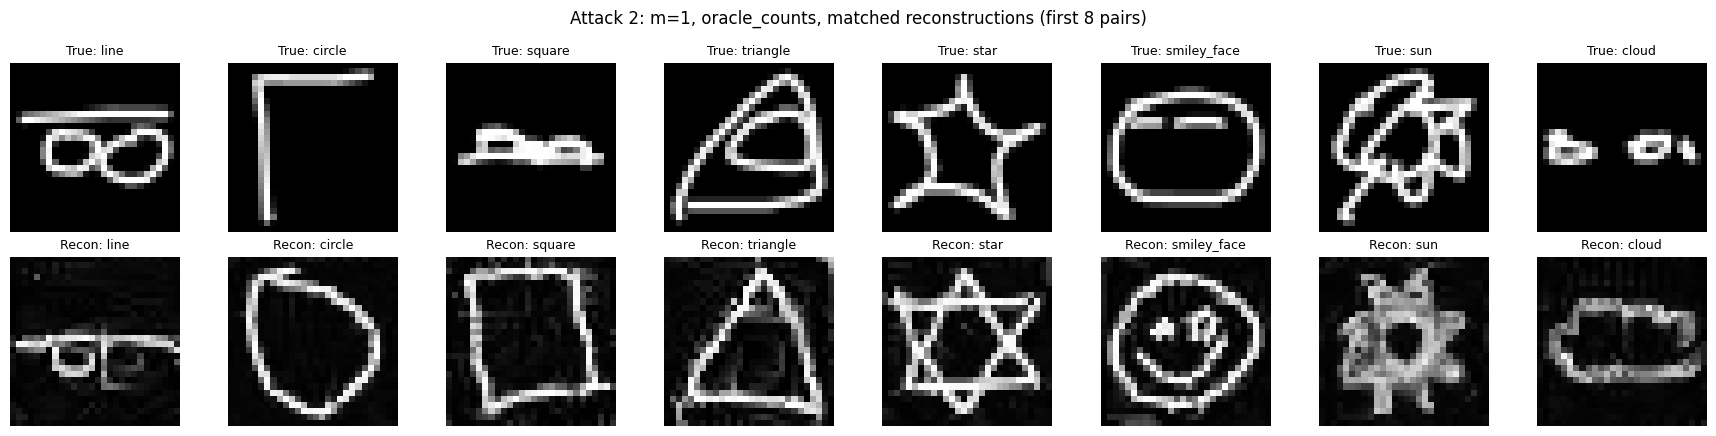


Reconstruction quality (matched labels only):
  matched=7/8, MSE=8615.64, PSNR=8.81, SSIM=0.212
Reconstruction quality (FULL metric, missed true labels penalized as blank):
  unmatched_true=1, extra_pred=1, MSE=8034.18, PSNR=9.23, SSIM=0.186


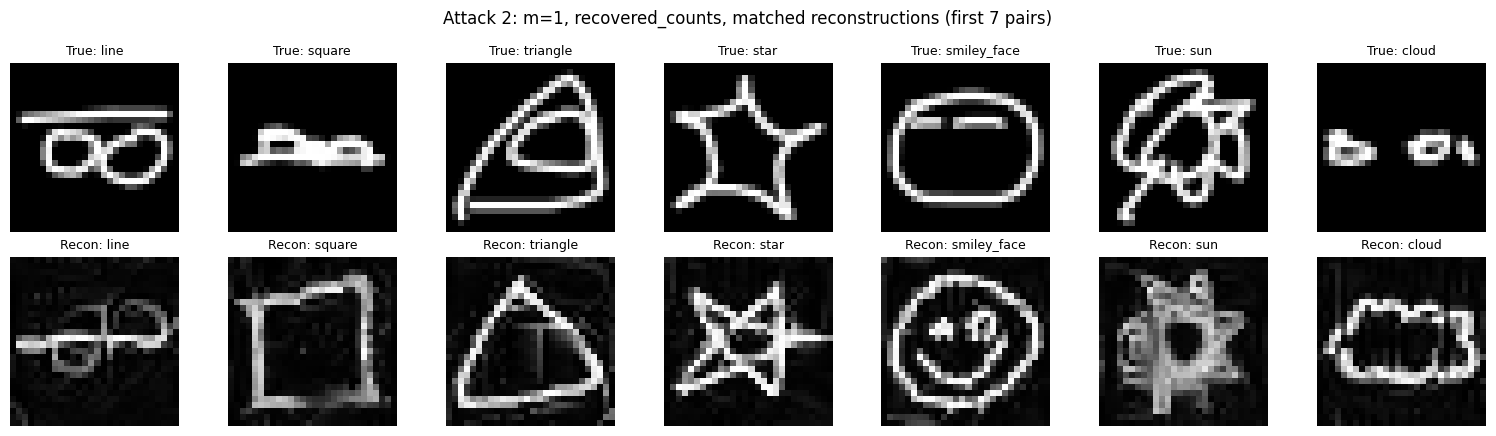


Runtime and peak memory for this aggregate attack experiment:
  Runtime: 393.91 s
  Peak process RAM (RSS): 1689.3 MiB (+333.8 MiB over start)
  Peak CUDA VRAM allocated: 100.2 MiB (+86.9 MiB)
  Peak CUDA VRAM reserved: 670.0 MiB (+30.0 MiB)
Saved Attack 2 m=1 results to: outputs_attack2_multi_user_v2/attack2_m1_results.json

Attack 2 experiment: m=2 participating client(s)
Participating clients: [0, 1]
Total private samples N=12
True aggregate label counts (evaluation only):
  line:1, circle:2, square:2, triangle:1, star:2, smiley_face:1, sun:1, cloud:2
Before FedAvg head update: loss=5.2773, acc=16.67%
After  FedAvg head update: loss=4.5725, acc=16.67%
Sanity check grad_W MSE(delta-derived vs aggregate): 0.000000000000
Sanity check grad_b MSE(delta-derived vs aggregate): 0.000000000000

Aggregate bias gradient sorted from most negative to most positive:
  4 star            -0.15891246
  2 square          -0.06677943
  3 triangle        -0.06338032
  1 circle          -0.02565064
  6

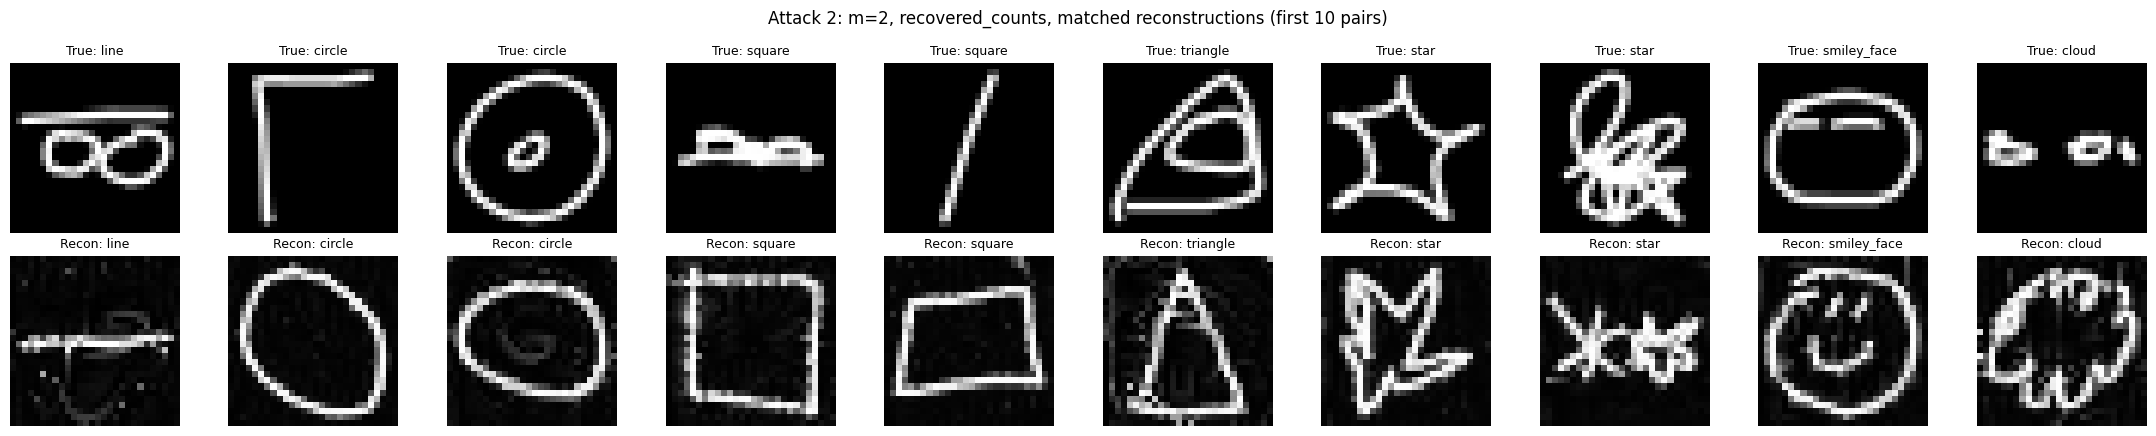


Runtime and peak memory for this aggregate attack experiment:
  Runtime: 86.00 s
  Peak process RAM (RSS): 1746.2 MiB (+56.9 MiB over start)
  Peak CUDA VRAM allocated: 139.9 MiB (+118.5 MiB)
  Peak CUDA VRAM reserved: 680.0 MiB (+10.0 MiB)
Saved Attack 2 m=2 results to: outputs_attack2_multi_user_v2/attack2_m2_results.json

Attack 2 experiment: m=5 participating client(s)
Participating clients: [0, 1, 2, 3, 4]
Total private samples N=28
True aggregate label counts (evaluation only):
  line:3, circle:4, square:4, triangle:3, star:4, smiley_face:3, sun:3, cloud:4
Before FedAvg head update: loss=5.2011, acc=7.14%
After  FedAvg head update: loss=4.9809, acc=7.14%
Sanity check grad_W MSE(delta-derived vs aggregate): 0.000000000000
Sanity check grad_b MSE(delta-derived vs aggregate): 0.000000000000

Aggregate bias gradient sorted from most negative to most positive:
  4 star            -0.11748707
  3 triangle        -0.05651084
  1 circle          -0.02975195
  6 smiley_face     -0.018874

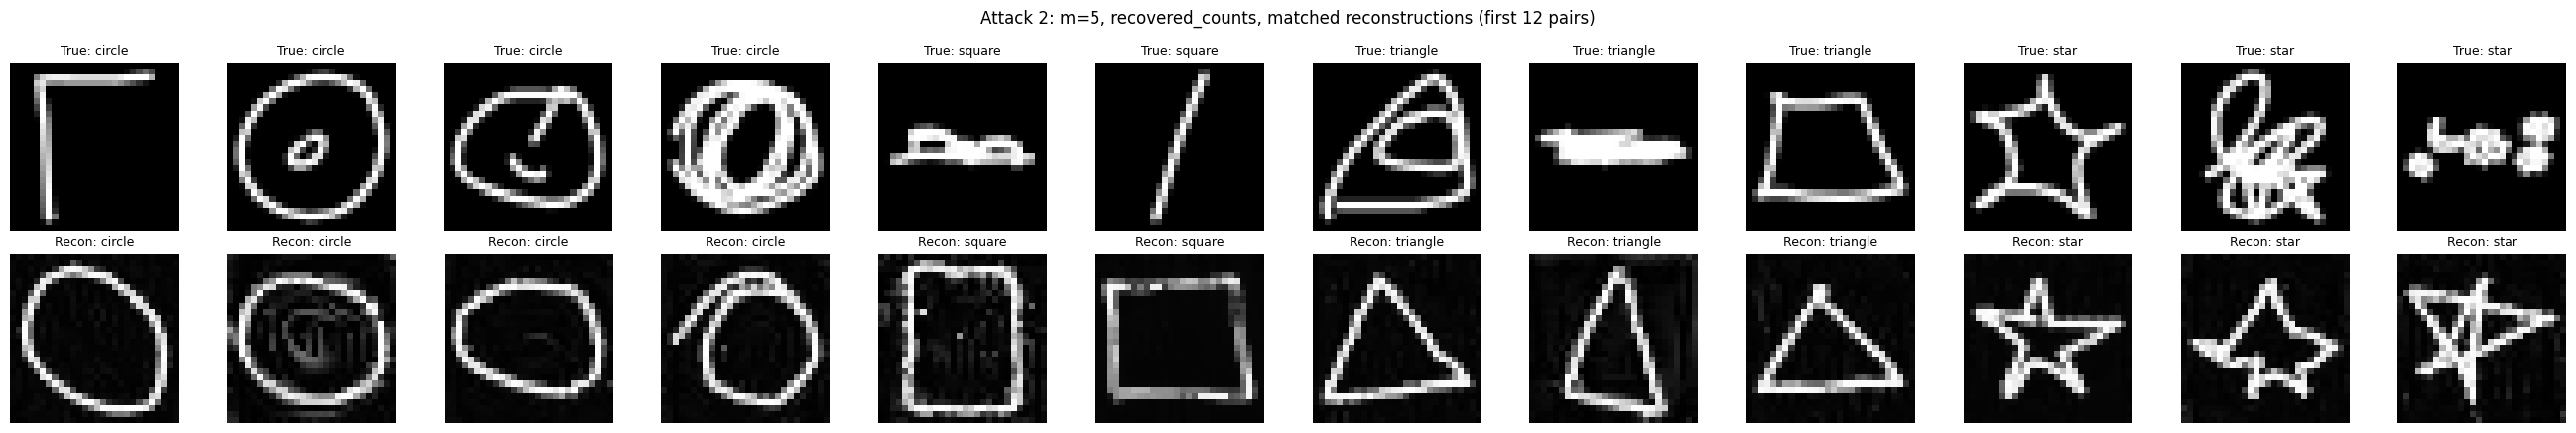


Runtime and peak memory for this aggregate attack experiment:
  Runtime: 53.12 s
  Peak process RAM (RSS): 1766.9 MiB (+42.2 MiB over start)
  Peak CUDA VRAM allocated: 297.7 MiB (+276.3 MiB)
  Peak CUDA VRAM reserved: 680.0 MiB (+0.0 MiB)
Saved Attack 2 m=5 results to: outputs_attack2_multi_user_v2/attack2_m5_results.json

Attack 2 experiment: m=10 participating client(s)
Participating clients: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Total private samples N=56
True aggregate label counts (evaluation only):
  line:8, circle:7, square:6, triangle:7, star:8, smiley_face:6, sun:6, cloud:8
Before FedAvg head update: loss=5.4388, acc=7.14%
After  FedAvg head update: loss=5.0353, acc=8.93%
Sanity check grad_W MSE(delta-derived vs aggregate): 0.000000000000
Sanity check grad_b MSE(delta-derived vs aggregate): 0.000000000000

Aggregate bias gradient sorted from most negative to most positive:
  4 star            -0.11483826
  3 triangle        -0.06721985
  6 smiley_face     -0.03983510
  2 square    

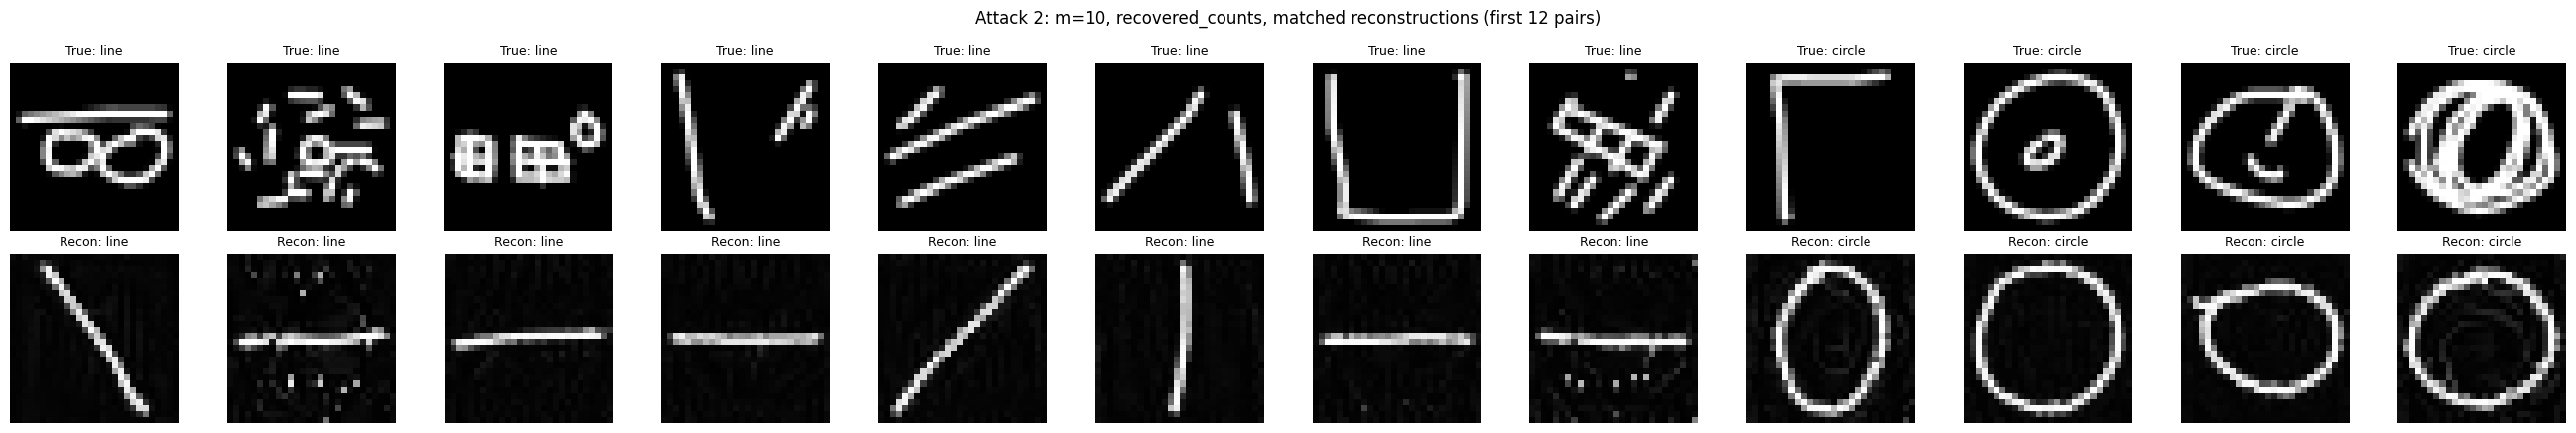


Runtime and peak memory for this aggregate attack experiment:
  Runtime: 33.86 s
  Peak process RAM (RSS): 1781.7 MiB (+40.1 MiB over start)
  Peak CUDA VRAM allocated: 571.3 MiB (+549.9 MiB)
  Peak CUDA VRAM reserved: 680.0 MiB (+0.0 MiB)
Saved Attack 2 m=10 results to: outputs_attack2_multi_user_v2/attack2_m10_results.json

Attack 2 summary table metric: FULL reconstruction metric with missed true labels penalized as blank
  m    N  Label-count acc (%)          MSE       PSNR     SSIM    matched   missed
  1    8                 87.5      8034.18       9.23    0.186          7        1
  2   12                 83.3     10285.06       8.08    0.097         10        2
  5   28                 75.0      8281.28       9.18    0.148         21        7
 10   56                 75.0      8611.48       9.07    0.164         42       14

LaTeX rows for Table~\ref{tab:attack2}:
1 & 8034.18 & 9.23 & 0.186 \
2 & 10285.06 & 8.08 & 0.097 \
5 & 8281.28 & 9.18 & 0.148 \
10 & 8611.48 & 9.07 & 0.16

In [10]:
all_results = []
for m in M_VALUES:
    result = run_attack_for_m(m)
    all_results.append(result)

summary_rows = []
for result in all_results:
    metric = result["table_metric_full_with_missed_as_blank"]
    summary_rows.append({
        "m": result["m_clients"],
        "N": result["n_total"],
        "label_count_accuracy_pct": result["label_count_accuracy_pct"],
        "mse": metric["mse"],
        "psnr_db": metric["psnr_db"],
        "ssim": metric["ssim"],
        "n_matched": result["evaluation"]["n_matched"],
        "n_unmatched_true": result["evaluation"]["n_unmatched_true"],
        "runtime_s": result["resource_stats"]["elapsed_s"],
        "peak_ram_mib": result["resource_stats"]["peak_process_ram_mib"],
        "peak_vram_allocated_mib": result["resource_stats"]["peak_cuda_vram_allocated_mib"],
    })

summary_path = OUTPUT_DIR / "attack2_summary.json"
save_json(summary_path, {"rows": summary_rows, "config": {
    "m_values": M_VALUES,
    "excluded_class_names": EXCLUDED_CLASS_NAMES,
    "attacker_knows_excluded_classes": ATTACKER_KNOWS_EXCLUDED_CLASSES,
    "min_images_per_client": MIN_IMAGES_PER_CLIENT,
    "max_images_per_client": MAX_IMAGES_PER_CLIENT,
    "local_lr": LOCAL_LR,
    "user_sample_mode": USER_SAMPLE_MODE,
    "public_grad_ref_per_class": PUBLIC_GRAD_REF_PER_CLASS,
    "count_recovery_bias_weight": COUNT_RECOVERY_BIAS_WEIGHT,
    "pixel_attack_steps_by_m": PIXEL_ATTACK_STEPS_BY_M,
    "pixel_attack_restarts_by_m": PIXEL_ATTACK_RESTARTS_BY_M,
    "pixel_attack_lr": PIXEL_ATTACK_LR,
    "pixel_grad_clip_norm": PIXEL_GRAD_CLIP_NORM,
    "run_oracle_count_pixel_diagnostic": RUN_ORACLE_COUNT_PIXEL_DIAGNOSTIC,
    "oracle_count_pixel_diagnostic_m_values": ORACLE_COUNT_PIXEL_DIAGNOSTIC_M_VALUES,
}})

print("\n" + "=" * 80)
print("Attack 2 summary table metric: FULL reconstruction metric with missed true labels penalized as blank")
print("=" * 80)
print(f"{'m':>3} {'N':>4} {'Label-count acc (%)':>20} {'MSE':>12} {'PSNR':>10} {'SSIM':>8} {'matched':>10} {'missed':>8}")
for row in summary_rows:
    print(f"{row['m']:>3d} {row['N']:>4d} {row['label_count_accuracy_pct']:>20.1f} "
          f"{row['mse']:>12.2f} {row['psnr_db']:>10.2f} {row['ssim']:>8.3f} "
          f"{row['n_matched']:>10d} {row['n_unmatched_true']:>8d}")

latex_rows = []
for row in summary_rows:
    latex_rows.append(f"{row['m']} & {row['mse']:.2f} & {row['psnr_db']:.2f} & {row['ssim']:.3f} \\")
latex_table = "\n".join(latex_rows)
latex_path = OUTPUT_DIR / "attack2_latex_rows.txt"
with open(latex_path, "w") as f:
    f.write(latex_table + "\n")

print("\nLaTeX rows for Table~\\ref{tab:attack2}:")
print(latex_table)
print(f"\nSaved summary to: {summary_path}")
print(f"Saved LaTeX rows to: {latex_path}")


## What this notebook demonstrates

The experiment isolates a specific server-side privacy question: **does FedAvg aggregation itself eliminate reconstruction leakage?**

In this controlled one-step, head-only setting, aggregation hides the individual client updates but still leaves an aggregate gradient-equivalent signal in the global model change. The reconstruction experiment measures how useful that signal remains as more users contribute to the same round.

The result should not be generalized to every FL configuration. Multiple local steps, full-model training, momentum or adaptive optimizers, client heterogeneity, larger local datasets, clipping, differential privacy, quantization, and other defenses change the information available in the aggregate update.
